# Lab 3 — Millions of TVs, Who Is Watching?
Name: Daryna Koval | Group: KM-42

## Setup

In [1]:
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
DATA = kagglehub.dataset_download("shkarupylomaxim/adtech-lab1-tv-panel/versions/4")
programs = pd.read_parquet(f"{DATA}/programs.parquet")
viewings = pd.read_parquet(f"{DATA}/viewings.parquet")
daily_weights = pd.read_parquet(f"{DATA}/daily_weights.parquet")
viewer_attributes = pd.read_parquet(f"{DATA}/viewer_attributes.parquet")
attributes = pd.read_parquet(f"{DATA}/attributes.parquet")
acr_sessions = pd.read_parquet(f"{DATA}/acr_sessions.parquet")
hh_attributes = pd.read_parquet(f"{DATA}/hh_attributes.parquet")
reference_ratings = pd.read_parquet(f"{DATA}/reference_ratings.parquet")

c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Task 1.1 — Five questions

**Answer:**

| | acr_sessions (smart TVs) | viewings (Lab 1 panel) |
|---|---|---|
| Grain | one session on one smart TV (until the network, program or input changes) | one viewing session of one person or one household TV on one of ten networks |
| Key | session_id; tv_id; hashed_ip links to hh_attributes | viewing_id; respondent_id links to weights and attributes |
| Coverage | 29,940 opted-in smart TVs, one per home, Oct 14-27, all networks, apps and unknown | about 4,000 households, all TVs and people in the home, October, ten networks |
| Weight | none: every TV counts once | daily weights that add up to all US homes and persons |
| Provenance | ACR: the TV matches the picture on screen to live feeds; homes that opted in | a panel recruited to represent the US; people meters |

The biggest difference is the **weight**. The panel is chosen to represent the US and has weights. The smart-TV data is just the homes that bought this TV and opted in, without weights, so it describes only these homes.

## Task 1.2 — Size and shape

In [2]:
def to_eastern(col):
    return pd.to_datetime(col, utc=True).dt.tz_convert("America/New_York").dt.tz_localize(None)

acr = acr_sessions.copy()
acr["start_ts"] = to_eastern(acr["start_utc"])
acr["end_ts"] = to_eastern(acr["end_utc"])
acr["bday"] = (acr["start_ts"] - pd.Timedelta(hours=6)).dt.normalize()
acr["hours"] = (acr["end_ts"] - acr["start_ts"]).dt.total_seconds() / 3600

ok = acr[acr["hours"] >= 1 / 60]
intab = ok.groupby("bday")["tv_id"].nunique()
tv_days = intab.sum()

print("TVs:", acr["tv_id"].nunique())
print("Sessions:", len(acr))
print("Broadcast days:", acr["bday"].nunique())
print("Average TVs in-tab per day:", round(intab.mean()))
print("Hours per TV per day, raw:", round(acr["hours"].sum() / tv_days, 2))
print("Hours per TV per day, after edit rule:", round(ok["hours"].sum() / tv_days, 2))
print("Share of sessions dropped:", f"{1 - len(ok) / len(acr):.3f}")

TVs: 29940
Sessions: 6392981
Broadcast days: 14
Average TVs in-tab per day: 29074
Hours per TV per day, raw: 4.74
Hours per TV per day, after edit rule: 4.7
Share of sessions dropped: 0.299


## Task 1.3 — What the TV could not see

In [3]:
total = ok["hours"].sum()
print((ok.groupby("session_type")["hours"].sum() / total).round(3))
print((ok.groupby("input_source")["hours"].sum() / total).round(3))
print(pd.crosstab(ok["input_source"], ok["session_type"], ok["hours"], aggfunc="sum", normalize="index").round(3))
unknown = ok.loc[ok["session_type"] == "unknown", "hours"].sum() / total
print("Share of TV-on hours unknown (%):", round(unknown * 100, 1))

session_type
app        0.257
dvr        0.025
live       0.322
unknown    0.396
Name: hours, dtype: float64
input_source
antenna             0.086
built_in_app        0.307
cable_box           0.276
game_or_disc        0.024
satellite_box       0.076
streaming_device    0.231
Name: hours, dtype: float64
session_type        app    dvr   live  unknown
input_source                                  
antenna           0.000  0.000  0.638    0.362
built_in_app      0.836  0.010  0.088    0.066
cable_box         0.000  0.054  0.616    0.330
game_or_disc      0.000  0.000  0.000    1.000
satellite_box     0.000  0.051  0.621    0.328
streaming_device  0.000  0.014  0.098    0.889
Share of TV-on hours unknown (%): 39.6


**Answer:** 39.6% of the time when the TV is on is unknown. A real feed can have more (66% in LG's sample) because it only recognizes what is in its library of live channels: local stations, small channels, on-demand and streaming shows are often missing. Menus, screensavers and technical gaps also end up as unknown. Two kinds of viewing that end up as unknown here: games and discs (100% unknown) and streaming through a box like Roku or Fire TV (89% unknown), because the TV sees only the picture from the HDMI port.

## Task 2.1 — Match

In [4]:
tvs = acr_sessions.groupby("tv_id")["hashed_ip"].first()
hh_per_ip = hh_attributes.groupby("hashed_ip")["household_id"].nunique()
k = tvs.map(hh_per_ip).fillna(0)

print("Matched to one household (%):", round((k == 1).mean() * 100, 1))
print("Shared IP, unresolved (%):", round((k > 1).mean() * 100, 1))
print("Not matched (%):", round((k == 0).mean() * 100, 1))
print("Most households on one IP:", int(k.max()))

Matched to one household (%): 65.2
Shared IP, unresolved (%): 11.8
Not matched (%): 22.9
Most households on one IP: 6


**Answer:** Only 65.2% of TVs match exactly one household. 11.8% share an IP with other households and 22.9% are not in the file, so about a third of the TVs have no demographics. An IP address is a weak key because it belongs to an internet connection, not to a home. Several homes can share one IP (an apartment building, a dorm), here up to 6. And a home's IP can change when the provider gives it a new one or the family moves.

## Task 2.2 — Profile

In [5]:
groups = {"Under $25k": "Under $50k", "$25k-$50k": "Under $50k",
          "$50k-$75k": "$50k-$100k", "$75k-$100k": "$50k-$100k",
          "$100k-$150k": "$100k+", "$150k+": "$100k+"}

matched = tvs[k == 1].to_frame().merge(hh_attributes, on="hashed_ip")

daily_weights["broadcast_date"] = pd.to_datetime(daily_weights["broadcast_date"])
hh_days = daily_weights[daily_weights["resp_type"] == "H"]
two = hh_days[hh_days["broadcast_date"].between("2024-10-14", "2024-10-27")]
hh_w = two.groupby("respondent_id")["weight"].mean()

va = viewer_attributes.merge(attributes, on="attr_id")
def attr(group):
    return va[va["attr_group"] == group].set_index("respondent_id")["attr_name"]

def compare(footprint, panel_groups):
    t = pd.DataFrame({
        "footprint share": footprint.value_counts(normalize=True),
        "panel share": hh_w.groupby(panel_groups, observed=True).sum() / hh_w.sum(),
    })
    t["index"] = t["footprint share"] / t["panel share"] * 100
    return t.round({"footprint share": 3, "panel share": 3, "index": 0})

print(compare(matched["region"], attr("Census region")))
print(compare(matched["income_band"].map(groups), attr("Household income").map(groups)))

           footprint share  panel share  index
Midwest              0.201        0.210   96.0
Northeast            0.150        0.170   88.0
South                0.383        0.379  101.0
West                 0.266        0.241  110.0
            footprint share  panel share  index
$100k+                0.421        0.350  120.0
$50k-$100k            0.320        0.289  111.0
Under $50k            0.259        0.361   72.0


**Answer:** The footprint is too rich. Homes with $100k+ have index 120, and homes under $50k only 72. By region the differences are smaller: the West is over-represented (110) and the Northeast under-represented (88). One reason: to be in this data, a home has to buy a new smart TV, connect it to the internet and agree to share data. Richer homes buy new TVs more often and have internet at home; poorer and older homes often don't.

## Task 2.3 — Ratings

In [6]:
def viewers(sessions, t):
    s = sessions[sessions["network_code"] == t["network_code"]]
    overlap = s["end_ts"].clip(upper=t["end_ts"]) - s["start_ts"].clip(lower=t["start_ts"])
    return s[overlap >= pd.Timedelta(minutes=1)]

programs["broadcast_date"] = pd.to_datetime(programs["broadcast_date"])
live = ok[ok["session_type"] == "live"]
tc = reference_ratings.merge(programs, on="telecast_id")

tv_rating = []
for _, t in tc.iterrows():
    tv_rating.append(viewers(live, t)["tv_id"].nunique() / intab[t["broadcast_date"]] * 100)
tc["TVs' HH rating"] = tv_rating
tc["reference HH rating"] = tc["hh_rating"]
tc["ratio"] = tc["TVs' HH rating"] / tc["hh_rating"]

table = tc.set_index("program_name")[["network_code", "TVs' HH rating", "reference HH rating", "ratio"]]
print(table.sort_values("ratio").round({"TVs' HH rating": 1, "reference HH rating": 1, "ratio": 3}))

                                     network_code  TVs' HH rating  reference HH rating  ratio
program_name                                                                                 
Hannity                                       FNC             0.8                  2.3  0.359
NCIS                                          CBS             5.4                 10.6  0.509
Unsellable Houses                            HGTV             2.1                  3.7  0.568
The Real Housewives of New York City        BRAVO             0.7                  1.2  0.600
Halloween Baking Championship                FOOD             1.0                  1.6  0.604
MLB Postseason                                FOX            16.5                 25.9  0.639
Grotesquerie                                   FX             2.3                  3.5  0.641
NFL Football                                  NBC            21.2                 33.1  0.641


In [7]:
age = va[va["attr_name"] == "Age in years"].set_index("respondent_id")["value"].astype(float)
heads = va[va["attr_name"] == "Head of house"][["respondent_id"]].copy()
heads["household"] = heads["respondent_id"] // 100 * 100
heads["age"] = heads["respondent_id"].map(age)
head_age = heads.groupby("household")["age"].first()
head_band = pd.cut(head_age, [17, 34, 49, 64, 200], labels=["18-34", "35-49", "50-64", "65+"])
print(compare(matched["head_age_band"], head_band))

       footprint share  panel share  index
18-34            0.196        0.190  104.0
35-49            0.348        0.303  115.0
50-64            0.263        0.240  110.0
65+              0.192        0.267   72.0


**Answer:** All TV ratings are too low, from 0.36 to 0.64 of the reference. One reason is the same for every telecast: we see only one TV per home and only live viewing. But the gap is different for different telecasts. Furthest off are Hannity on Fox News (0.36) and NCIS on CBS (0.51), which older people watch. Closest are FX, NFL and the World Series (0.64), with younger audiences or sports. This fits the profile: the footprint has too few older homes (head of household 65+: index 72), so programs for older viewers lose the most.

## Task 3.1 — Hours per home

In [8]:
ten = ["CBS", "NBC", "ABC", "FOX", "FNC", "FX", "BRAVO", "HGTV", "FOOD", "HIST"]
tv_live = live[live["network_code"].isin(ten)]

hv = viewings[viewings["resp_type"] == "H"].copy()
hv["bday"] = (hv["start_ts"] - pd.Timedelta(hours=6)).dt.normalize()
hv = hv[hv["bday"].between("2024-10-14", "2024-10-27")]
hv["w_hours"] = (hv["end_ts"] - hv["start_ts"]).dt.total_seconds() / 3600 * hv["weight"]

tv_hours = tv_live["hours"].sum() / tv_days
panel_hours = hv["w_hours"].sum() / two["weight"].sum()
print("Live hours per TV per day (ten networks):", round(tv_hours, 2))
print("Live hours per panel household per day (ten networks):", round(panel_hours, 2))
print("TV / panel:", round(tv_hours / panel_hours, 2))

Live hours per TV per day (ten networks): 0.87
Live hours per panel household per day (ten networks): 1.92
TV / panel: 0.45


**Answer:** The smart TVs show much less: 0.87 hours per TV per day against 1.92 per panel home, about 45%. The main reason: a home has about 2.6 TVs, and only about 1.1 of them is this brand. We see only one TV, while the panel measures all TVs in the home. Also, some viewing of these networks is not recognized as live (it ends up as unknown or DVR).

## Task 3.2 — Network shares

In [9]:
shares = pd.DataFrame({
    "share in TVs": tv_live.groupby("network_code")["hours"].sum() / tv_live["hours"].sum(),
    "share in panel": hv.groupby("network_code")["w_hours"].sum() / hv["w_hours"].sum(),
})
shares["index"] = shares["share in TVs"] / shares["share in panel"] * 100
print(shares.sort_values("index").round({"share in TVs": 3, "share in panel": 3, "index": 0}))

              share in TVs  share in panel  index
network_code                                     
FNC                  0.085           0.110   77.0
CBS                  0.182           0.196   93.0
NBC                  0.214           0.206  104.0
HIST                 0.019           0.019  104.0
FOX                  0.201           0.194  104.0
ABC                  0.196           0.187  105.0
FOOD                 0.024           0.022  109.0
HGTV                 0.034           0.031  110.0
BRAVO                0.016           0.013  122.0
FX                   0.028           0.022  129.0


**Answer:** The smart-TV data understates Fox News the most (index 77) and CBS (93), networks with older audiences. It overstates FX (129) and Bravo (122), which have younger audiences. This is the same pattern as in Task 2.3: too few older homes in the footprint.

## Task 3.3 — What each can see

**Answer:**

What the panel can see and the smart TVs cannot:
1. **People:** who is watching (age, sex), so we can rate groups like A18-49. A TV only knows it is on.
2. **All TVs in the home**, not only one (Task 3.1).
3. **The whole US:** homes without a smart TV or internet, older and poorer homes, with weights (Task 2.2).

What the smart TVs can see and the panel's ten-network files cannot:
1. **All networks**: more than 50 (ESPN, CNN, TBS and others), not only ten.
2. **Everything else on the screen**: streaming apps, games, discs and unknown time.
3. **Many more homes**: about 30,000 TVs instead of about 4,000 homes, with exact times and the TV's market (DMA).

## Task 4.1 — Daily plots

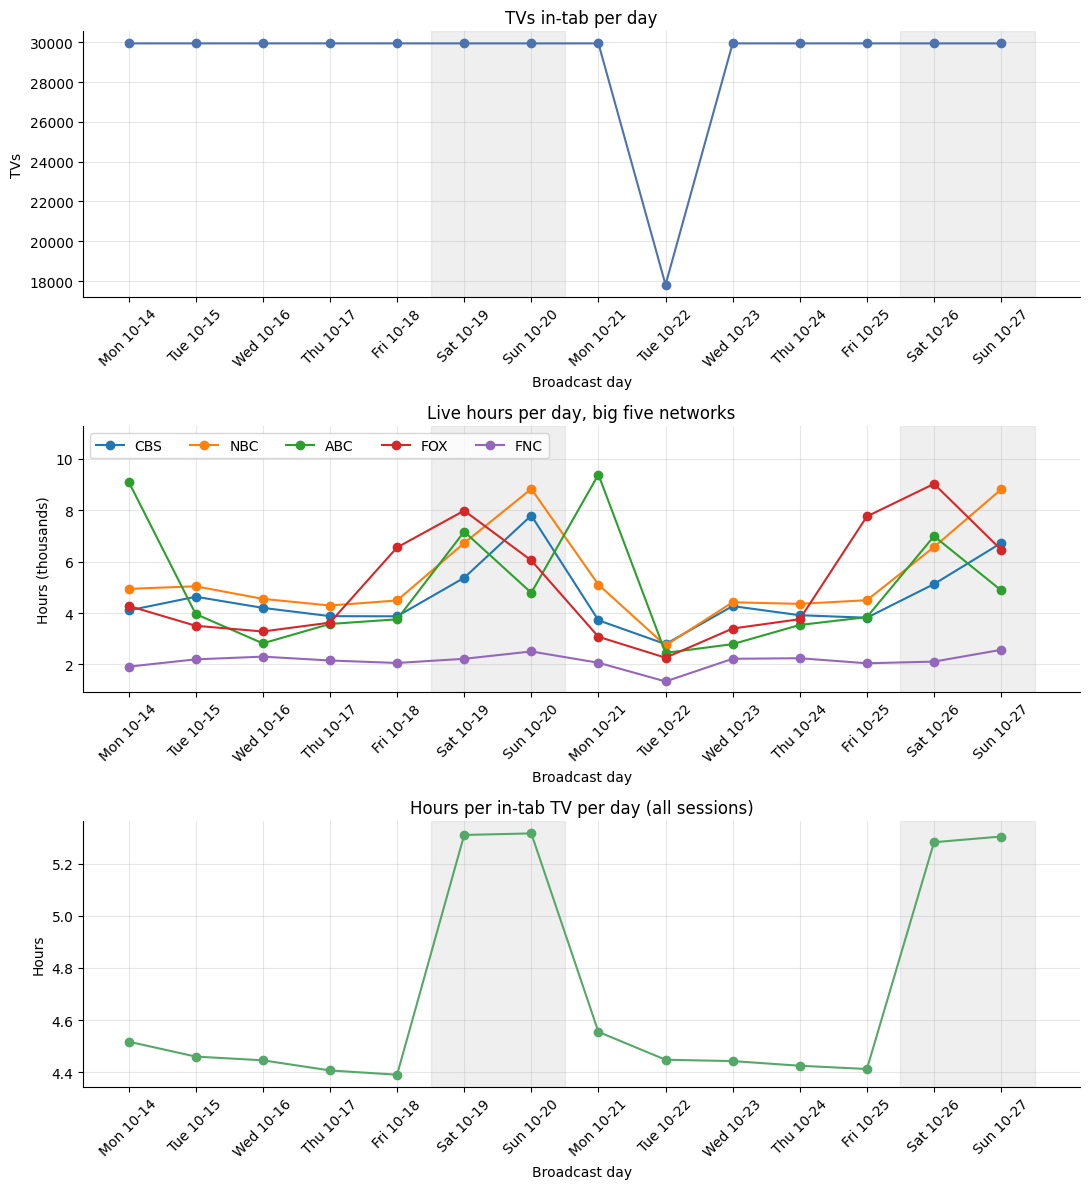

In [10]:
big = ["CBS", "NBC", "ABC", "FOX", "FNC"]
daily = live[live["network_code"].isin(big)].groupby(["bday", "network_code"])["hours"].sum().unstack()
per_tv = ok.groupby("bday")["hours"].sum() / intab

days = intab.index
fig, ax = plt.subplots(3, 1, figsize=(11, 12))
ax[0].plot(intab, marker="o", color="#4C72B0")
ax[0].set_title("TVs in-tab per day")
ax[0].set_ylabel("TVs")
for net in big:
    ax[1].plot(daily[net] / 1000, marker="o", label=net)
ax[1].set_title("Live hours per day, big five networks")
ax[1].set_ylabel("Hours (thousands)")
ax[1].set_ylim(top=daily.max().max() / 1000 * 1.2)
ax[1].legend(ncol=5, loc="upper left")
ax[2].plot(per_tv, marker="o", color="#55A868")
ax[2].set_title("Hours per in-tab TV per day (all sessions)")
ax[2].set_ylabel("Hours")
for a in ax:
    for sat in days[days.dayofweek == 5]:
        a.axvspan(sat - pd.Timedelta(hours=12), sat + pd.Timedelta(hours=36), color="grey", alpha=0.12)
    a.set_xticks(days)
    a.set_xticklabels(days.strftime("%a %m-%d"), rotation=45)
    a.set_xlabel("Broadcast day")
    a.grid(alpha=0.3)
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

## Task 4.2 — Spike and broken day

In [11]:
spike_day, spike_net = daily.stack().idxmax()
print("Biggest spike (date, network):", spike_day.strftime("%Y-%m-%d"), spike_net)
evening = programs[(programs["network_code"] == spike_net) & (programs["broadcast_date"] == spike_day)
                   & (programs["start_ts"].dt.hour >= 19)]
print(evening[["program_name", "episode_name", "start_ts", "end_ts"]].to_string(index=False))

broken = intab.idxmin()
print("Broken day (date):", broken.strftime("%Y-%m-%d"))
print("TVs in-tab that day:", intab[broken], "of", len(tvs))
other_weekdays = per_tv[(per_tv.index.dayofweek < 5) & (per_tv.index != broken)]
print("Hours per in-tab TV that day:", round(per_tv[broken], 2), "| other weekdays:", round(other_weekdays.mean(), 2))

tv_input = ok.drop_duplicates("tv_id").set_index("tv_id")["input_source"]
seen = ok.loc[ok["bday"] == broken, "tv_id"].unique()
print(pd.DataFrame({"missing TVs": tv_input.drop(seen).value_counts(normalize=True),
                    "all TVs": tv_input.value_counts(normalize=True)}).round(3))

Biggest spike (date, network): 2024-10-21 ABC
                  program_name           episode_name            start_ts              end_ts
Local / Syndicated Programming                   None 2024-10-21 19:00:00 2024-10-21 20:00:00
 Who Wants to Be a Millionaire                   None 2024-10-21 20:00:00 2024-10-21 20:15:00
                  NFL Football NFL Football: BAL @ TB 2024-10-21 20:15:00 2024-10-21 23:25:00
Local / Syndicated Programming                   None 2024-10-21 23:25:00 2024-10-22 00:35:00
Broken day (date): 2024-10-22
TVs in-tab that day: 17818 of 29940
Hours per in-tab TV that day: 4.45 | other weekdays: 4.45
                  missing TVs  all TVs
input_source                          
built_in_app            0.405    0.409
streaming_device        0.297    0.298
cable_box               0.170    0.165
antenna                 0.055    0.055
satellite_box           0.047    0.046
game_or_disc            0.026    0.026


**Answer:** The biggest spike is ABC on Monday, October 21: Monday Night Football (Baltimore at Tampa Bay). ABC had the same jump on Monday, October 14, and FOX goes up from October 25 with the World Series. These are real events: one network goes up, but the number of in-tab TVs stays the same.

The broken day is Tuesday, October 22. Only 17,818 of 29,940 TVs sent data, so all networks fall by about 40% at once. But hours per in-tab TV are normal (4.45, like other weekdays), and the missing TVs look like all the others. So the audience did not change; part of the data was not delivered.

If nobody noticed, daily totals for October 22 would be about 40% too low, and so would a rating that divides by all 29,940 TVs instead of that day's in-tab TVs. I would **flag** the day, not drop it: ratings per in-tab TV are still fine because the missing TVs look random, but its totals should not be compared with other days.

## Task 5.1 — Sampling error vs bias

In [12]:
n_panel = hh_days.groupby("broadcast_date").size()
se = tc[tc["program_name"].isin(["NFL Football", "Hannity", "Unsellable Houses"])].set_index("program_name")
p = se["hh_rating"] / 100

errors = pd.DataFrame({
    "SE footprint": (p * (1 - p) / se["broadcast_date"].map(intab)) ** 0.5 * 100,
    "SE panel": (p * (1 - p) / se["broadcast_date"].map(n_panel)) ** 0.5 * 100,
    "TVs' rating - reference": se["TVs' HH rating"] - se["hh_rating"],
})
errors["gap / SE footprint"] = errors["TVs' rating - reference"].abs() / errors["SE footprint"]
print(errors.round(2))
print("SE panel / SE footprint:", round((errors["SE panel"] / errors["SE footprint"]).mean(), 1))

                   SE footprint  SE panel  TVs' rating - reference  gap / SE footprint
program_name                                                                          
NFL Football               0.27      0.75                   -11.89               43.71
Hannity                    0.09      0.24                    -1.48               17.03
Unsellable Houses          0.11      0.30                    -1.59               14.62
SE panel / SE footprint: 2.8


**Answer:** The footprint's sampling error is about 2.8 times smaller than the panel's (0.27 vs 0.75 points for Sunday Night Football), because it has about 30,000 TVs instead of about 3,900 homes. But the gap to the reference is much bigger: -11.9 points for Sunday Night Football, -1.5 for Hannity, -1.6 for Unsellable Houses, 15 to 44 times the SE. So the bias is the bigger error, and more data does not fix it. More TVs make the sampling error smaller, but the bias comes from who is in the data (too few older homes) and what it sees (one TV, live only). A big sample is not the same as a representative one.

## Task 5.2 — Answer to the planner

**Answer:** For tomorrow I would give the currency rating for Sunday Night Football, 33.1, not the feed's number. The feed shows only 21.2, which is not a US household rating but the share of this brand's smart TVs that watched, and it is more than a third too low. The feed does not see people, other TVs in the home, streaming and unknown viewing, homes that did not opt in and the 35% of TVs that did not match. Its homes are also richer and younger than the US, and more TVs would not fix that. Before using it for planning we need weights that make it look like the US, a correction for other TVs in the home, a check against the currency on many telecasts, and flags for broken days like October 22.

## Bonus

In [13]:
snf = tc[tc["program_name"] == "NFL Football"].iloc[0]
watched = viewers(viewings, snf).drop_duplicates("respondent_id")
hh_watched = watched[watched["resp_type"] == "H"]
a2554_watched = watched[watched["respondent_id"].map(age).between(25, 54)]
vpvh = a2554_watched["weight"].sum() / hh_watched["weight"].sum()

day = daily_weights[daily_weights["broadcast_date"] == snf["broadcast_date"]]
us_hh = day.loc[day["resp_type"] == "H", "weight"].sum()
us_a2554 = day.loc[day["respondent_id"].map(age).between(25, 54), "weight"].sum()

print("VPVH A25-54:", round(vpvh, 3))
print("A25-54 rating (persons):", round(snf["TVs' HH rating"] * vpvh * us_hh / us_a2554, 1))
print("Same with the reference HH rating:", round(snf["hh_rating"] * vpvh * us_hh / us_a2554, 1))

VPVH A25-54: 0.513
A25-54 rating (persons): 11.1
Same with the reference HH rating: 17.3


**Answer:** VPVH from the panel is 0.513 adults 25-54 per viewing home. With the TVs' household rating of 21.2 this gives an A25-54 rating of about 11.1 (with the reference rating of 33.1 it would be 17.3, so the household error goes straight into the persons rating). This assumes that the footprint's viewing homes have the same people as the panel's viewing homes: the same number of adults 25-54 watching. But the footprint has fewer older and more richer homes, so this may not be true.